In [2]:
# Import Raw Dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load raw dataset (uses ';' as separator in dataset)
df_raw = pd.read_csv("../data/raw/marketing_campaign.csv", sep=";")
print("Raw shape:", df_raw.shape)
df_raw.head()

Raw shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


In [5]:
# Checking statistical audit of all 29 Columns

# 1. Full numeric audit table (min, quartiles, max, std)
audit_table = df_raw.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
display(audit_table)

# 2. Check categorical value counts (Education and Marital_Status)
print("--- Education Counts ---")
print(df_raw["Education"].value_counts())

print("\n--- Marital_Status Counts ---")
print(df_raw["Marital_Status"].value_counts())

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


--- Education Counts ---
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

--- Marital_Status Counts ---
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


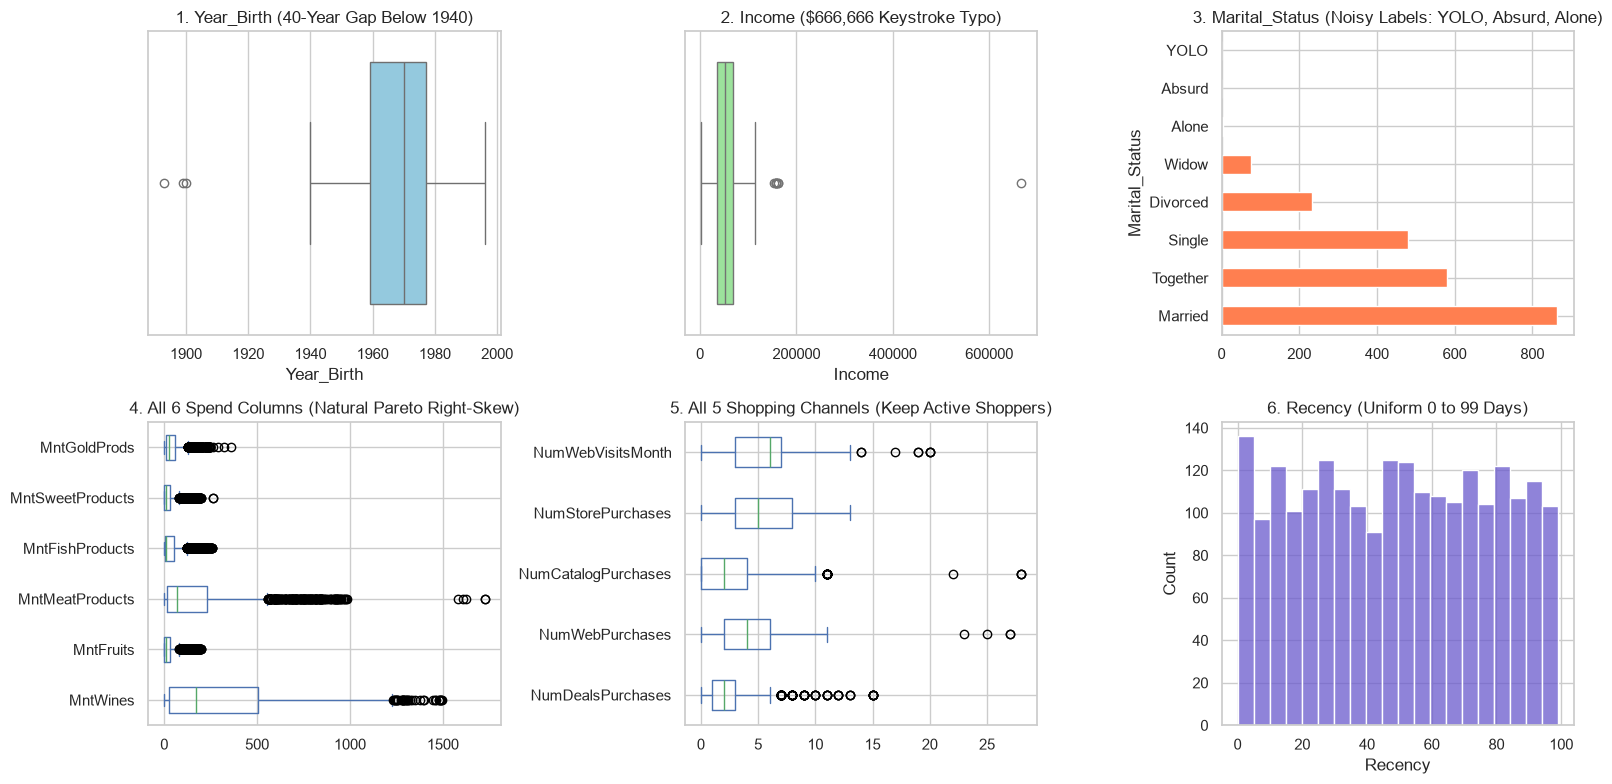

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# True data anomalities (Top ROW)
sns.boxplot(x=df_raw["Year_Birth"], ax=axes[0, 0], color="skyblue")
axes[0, 0].set_title("1. Year_Birth (40-Year Gap below the 1940 mark")

sns.boxplot(x=df_raw["Income"], ax=axes[0, 1], color="lightgreen")
axes[0, 1].set_title("2. Income")

df_raw["Marital_Status"].value_counts().plot(kind="barh", ax=axes[0, 2], color="coral")
axes[0, 2].set_title("3. Marital_Status (Noisy Labels: YOLO, Absurd, Alone)")


# Heavy-skewed Cuonsumer Behaviour (Bottom ROW)
spend_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
df_raw[spend_cols].plot(kind="box", ax=axes[1, 0], vert=False)
axes[1, 0].set_title("4. All 6 Spend Columns (Natural Pareto Right-Skew)")

channel_cols = ["NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth"]
df_raw[channel_cols].plot(kind="box", ax=axes[1, 1], vert=False)
axes[1, 1].set_title("5. All 5 Shopping Channels (Keep Active Shoppers)")

sns.histplot(df_raw["Recency"], bins=20, ax=axes[1, 2], color="slateblue")
axes[1, 2].set_title("6. Recency (Uniform 0 to 99 Days)")

plt.tight_layout()
plt.savefig("../outputs/figures/01_data_audit_overview.png")
plt.show()

In [13]:
# Forensic Check: Univariate and Cross-Feature Anomalies
spend_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
df_check = df_raw.copy()
df_check["Total_Spend"] = df_check[spend_cols].sum(axis=1)
df_check["Active_Channel_Purchases"] = df_check[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)

print("1. OLDEST BIRTH YEARS:")
print(df_check[["ID", "Year_Birth", "Kidhome", "Teenhome", "Income"]].sort_values("Year_Birth").head(5))

print("\n2. HIGHEST INCOMES:")
print(df_check[["ID", "Year_Birth", "Income", "Total_Spend"]].sort_values("Income", ascending=False).head(5))

print("\n3. CROSS-FEATURE IMPOSSIBLE ROWS (Ultra-low Income < $5,500 with huge Meat/Gold spend):")
print(df_check.sort_values("Income").head(6)[["ID", "Income", "Total_Spend", "MntMeatProducts", "MntGoldProds", "Active_Channel_Purchases"]])

1. OLDEST BIRTH YEARS:
         ID  Year_Birth  Kidhome  Teenhome   Income
239   11004        1893        0         1  60182.0
339    1150        1899        0         0  83532.0
192    7829        1900        1         0  36640.0
1950   6663        1940        0         0  51141.0
424    6932        1941        0         0  93027.0

2. HIGHEST INCOMES:
        ID  Year_Birth    Income  Total_Spend
2233  9432        1977  666666.0           62
617   1503        1976  162397.0          107
687   1501        1982  160803.0         1717
1300  5336        1971  157733.0           59
164   8475        1973  157243.0         1608

3. CROSS-FEATURE IMPOSSIBLE ROWS (Ultra-low Income < $5,500 with huge Meat/Gold spend):
         ID  Income  Total_Spend  MntMeatProducts  MntGoldProds  \
1245   6862  1730.0            8                3             1   
21     5376  2447.0         1730             1725             1   
1524  11110  3502.0            5                1             1   
1846   9931

In [14]:
# Clean the dataset (Univariate IQR used, and set cross-feature consistency rule)

df = df_raw.copy()

# 1. Drop 24 rows with missing Income
df = df.dropna(subset=["Income"])

# 2. Extreme Tukey IQR Bounds (k = 3.0) for Year_Birth and Income
q1_b, q3_b = df["Year_Birth"].quantile([0.25, 0.75])
lower_birth = q1_b - 3.0 * (q3_b - q1_b)   # 1905.0

q1_i, q3_i = df["Income"].quantile([0.25, 0.75])
upper_inc = q3_i + 3.0 * (q3_i - q1_i)     # $168,179

df = df[(df["Year_Birth"] >= lower_birth) & (df["Income"] <= upper_inc)]

# 3. Engineer Spend and Channel totals to filter cross-feature impossible rows
df["Total_Spend"] = df[spend_cols].sum(axis=1)
df["Active_Channel_Purchases"] = df[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)

# Drop rows where 2-year store spend exceeds 40% of annual income (catches ID=5376 spending $1,725 on meat with $2,447 income)
# AND drop rows where customer spent money but made 0 purchases across Web, Catalog, and Store
df = df[(df["Total_Spend"] <= 0.40 * df["Income"]) & (df["Active_Channel_Purchases"] > 0)]

# 4. Standardize noisy Marital_Status labels & drop constant columns (Z_CostContact, and Z_Revenue)
df["Marital_Status"] = df["Marital_Status"].replace({"Alone": "Single", "Absurd": "Single", "YOLO": "Single"})
df = df.drop(columns=["Z_CostContact", "Z_Revenue"])

# 5. Final Feature Engineering
df["Age"] = 2014 - df["Year_Birth"]
df["Children"] = df["Kidhome"] + df["Teenhome"]
df["Total_Purchases"] = df[channel_cols[:4]].sum(axis=1)
df["Income_Bracket"] = pd.cut(
    df["Income"],
    bins=[0, 30000, 50000, 70000, 200000],
    labels=["Low (<30k)", "Mid-Low (30k-50k)", "Mid-High (50k-70k)", "High (>70k)"]
)

print("Final Clean Dataset Shape:", df.shape)

Final Clean Dataset Shape: (2205, 33)


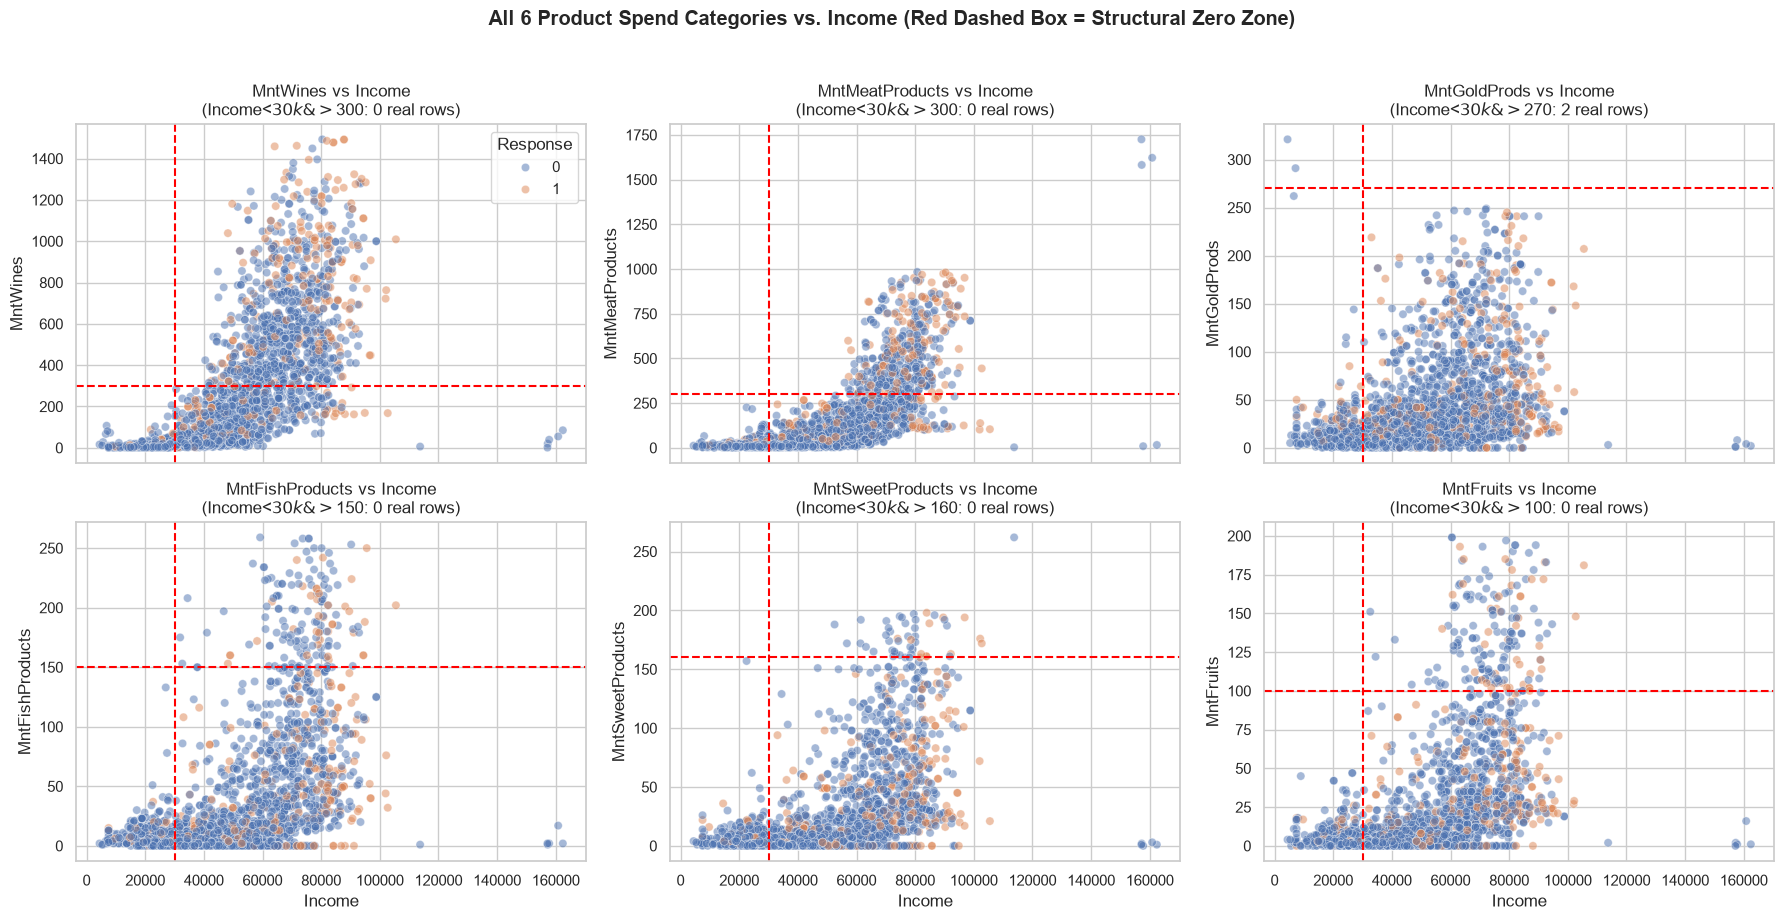

In [16]:
# Check all 6 Mnt* categories vs Income

# Empirical structural zero ceilings when Income < $30,000
sz_ceilings = {
    "MntWines": 300,
    "MntMeatProducts": 300,
    "MntGoldProds": 270,
    "MntFishProducts": 150,
    "MntSweetProducts": 160,
    "MntFruits": 100
}

fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharex=True)
axes = axes.flatten()

for i, (col, ceiling) in enumerate(sz_ceilings.items()):
    sns.scatterplot(data=df, x="Income", y=col, hue="Response", alpha=0.5, ax=axes[i], legend=(i == 0))
    axes[i].axvline(30000, color="red", linestyle="--")
    axes[i].axhline(ceiling, color="red", linestyle="--")
    
    # Count real customers in the top-left structural zero box (Income < $30k & Spend > ceiling)
    n_viol = ((df["Income"] < 30000) & (df[col] > ceiling)).sum()
    axes[i].set_title(f"{col} vs Income\n(Income<$30k & >${ceiling}: {n_viol} real rows)")

plt.suptitle("All 6 Product Spend Categories vs. Income (Red Dashed Box = Structural Zero Zone)", y=1.02, fontweight="bold")
plt.tight_layout()
plt.savefig("../outputs/figures/02_all_mnt_structural_zeros.png")
plt.show()

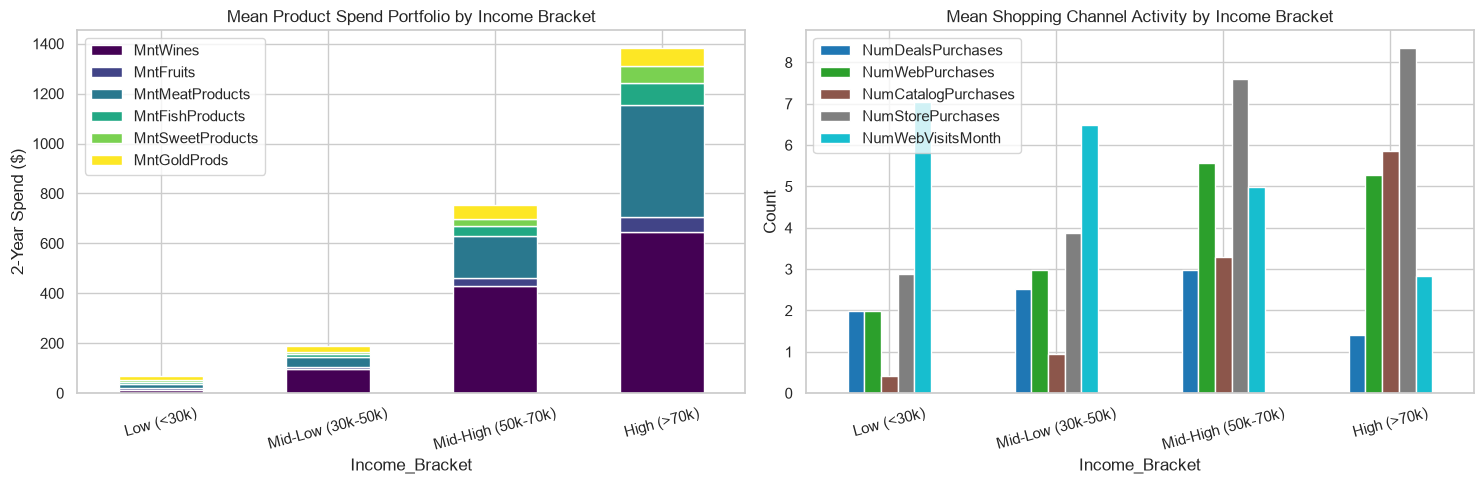

In [17]:
# Behavioral Pattern Discovery: Product Portfolio and channel usage across the income tiers

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Mean Product Spending by Income Bracket
df.groupby("Income_Bracket", observed=False)[spend_cols].mean().plot(
    kind="bar", stacked=True, ax=axes[0], colormap="viridis"
)
axes[0].set_title("Mean Product Spend Portfolio by Income Bracket")
axes[0].set_ylabel("2-Year Spend ($)")
axes[0].tick_params(axis="x", rotation=15)

# 2. Mean Shopping Channel Usage by Income Bracket
df.groupby("Income_Bracket", observed=False)[channel_cols].mean().plot(
    kind="bar", ax=axes[1], colormap="tab10"
)
axes[1].set_title("Mean Shopping Channel Activity by Income Bracket")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("../outputs/figures/03_spend_and_channel_shifts.png")
plt.show()

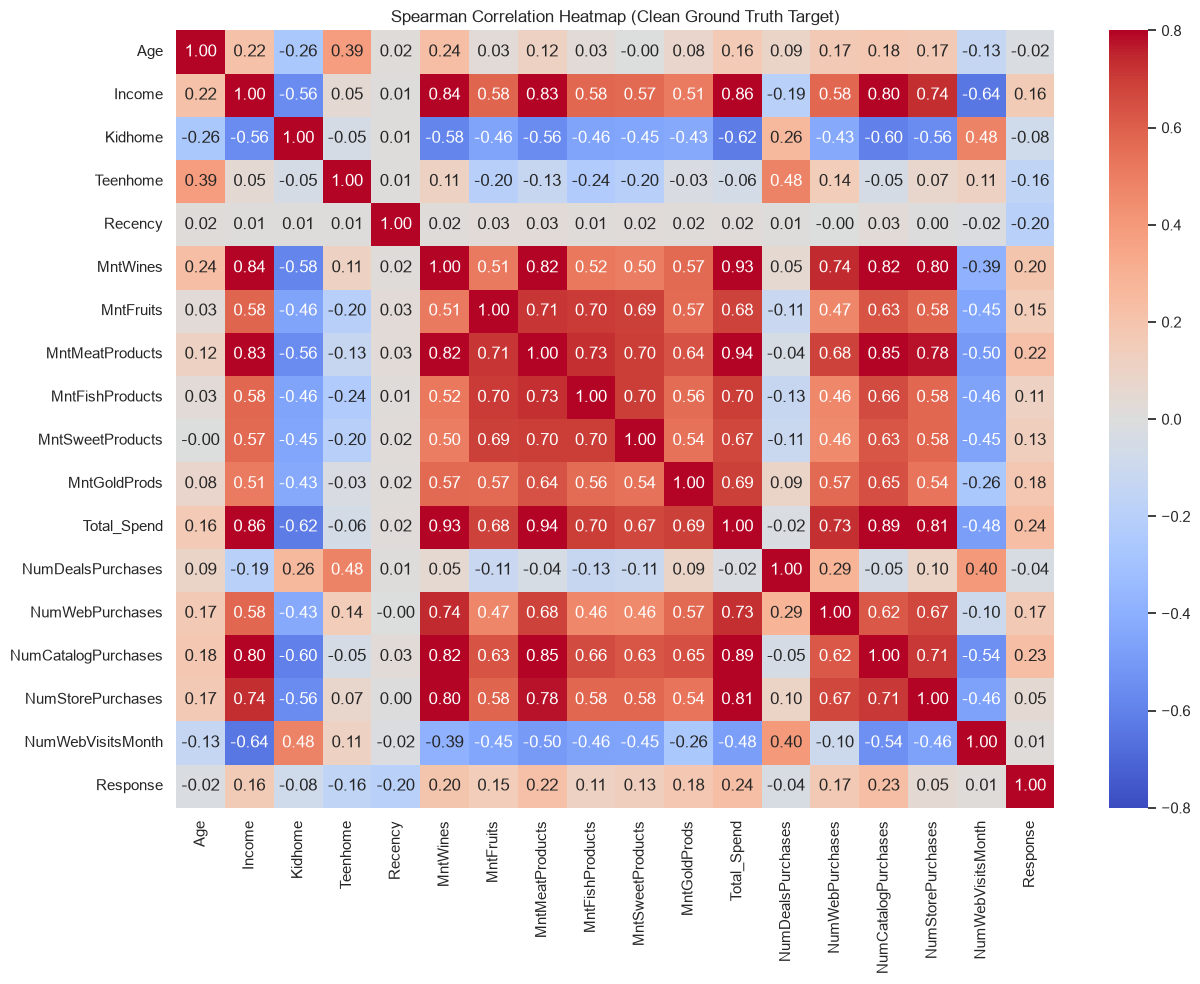

In [18]:
# Ground Truth : Spearman Coorelation matrix

corr_cols = [
    "Age", "Income", "Kidhome", "Teenhome", "Recency",
    "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds",
    "Total_Spend", "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases",
    "NumWebVisitsMonth", "Response"
]

plt.figure(figsize=(13, 10))
sns.heatmap(
    df[corr_cols].corr(method="spearman"),
    annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.8, vmax=0.8
)
plt.title("Spearman Correlation Heatmap (Clean Ground Truth Target)")
plt.tight_layout()
plt.savefig("../outputs/figures/04_correlation_heatmap.png")
plt.show()

Saved Clean: 2205 rows | Train: 1764 rows | Test: 441 rows


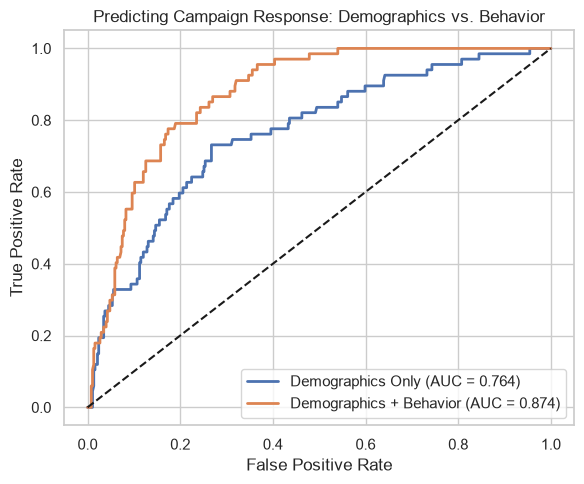

In [19]:
# Save an 80/20 Train/Test Split and Prove Behaviour + Demographic outperforms Demographic only

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

# 1. Stratified 80/20 Train/Test Split & Save to ../data/processed/
train_df, test_df = train_test_split(df, test_size=0.20, stratify=df["Response"], random_state=42)

df.to_csv("../data/processed/marketing_clean.csv", index=False)
train_df.to_csv("../data/processed/marketing_train.csv", index=False)
test_df.to_csv("../data/processed/marketing_test.csv", index=False)
print(f"Saved Clean: {len(df)} rows | Train: {len(train_df)} rows | Test: {len(test_df)} rows")

# 2. Compare Demographics Only vs. Demographics + Behavior for predicting Response
demo_cols = ["Age", "Income", "Kidhome", "Teenhome"]
behav_cols = demo_cols + spend_cols + channel_cols + ["Recency"]
cat_cols = ["Education", "Marital_Status"]

def get_roc(num_features):
    prep = ColumnTransformer([
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(drop="first"), cat_cols)
    ])
    X_train = prep.fit_transform(train_df)
    X_test = prep.transform(test_df)
    
    clf = LogisticRegression(max_iter=1000).fit(X_train, train_df["Response"])
    probs = clf.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(test_df["Response"], probs)
    fpr, tpr, _ = roc_curve(test_df["Response"], probs)
    return auc, fpr, tpr

auc_demo, fpr_d, tpr_d = get_roc(demo_cols)
auc_behav, fpr_b, tpr_b = get_roc(behav_cols)

plt.figure(figsize=(6, 5))
plt.plot(fpr_d, tpr_d, lw=2, label=f"Demographics Only (AUC = {auc_demo:.3f})")
plt.plot(fpr_b, tpr_b, lw=2, label=f"Demographics + Behavior (AUC = {auc_behav:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Predicting Campaign Response: Demographics vs. Behavior")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../outputs/figures/05_demo_vs_behavior_roc.png")
plt.show()